---
# **Pokédex AI**
## **01. Preparación de Datos**
---

### **1. Entorno y Configuración**

In [1]:
%pip install -q kagglehub cairosvg

# Bibliotecas estándar de Python.
import hashlib
import json
import math
import os
from datetime import datetime, timezone
from io import BytesIO
from itertools import combinations
from pathlib import Path
from tempfile import TemporaryDirectory
from zipfile import ZIP_DEFLATED, ZipFile

# Descarga, análisis y visualización.
import cairosvg
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Procesamiento de imágenes y separación de los datos.
from PIL import Image, ImageFile, ImageOps
from scipy.fft import dctn
from sklearn.model_selection import StratifiedGroupKFold

In [2]:
# Datos y reproducibilidad.
DATASET_HANDLE = "lantian773030/pokemonclassification"
DATASET_VERSION = 1
SEED = 42
SUPPORTED_EXTENSIONS = {".jpg", ".jpeg", ".png", ".gif", ".webp", ".svg"}

# Transformación determinista. El tamaño se expresa como (ancho, alto).
TARGET_SIZE = (224, 224)
BACKGROUND_COLOR = (255, 255, 255)

# Dos hashes perceptuales deben coincidir suficiente para proponer similitud.
PHASH_THRESHOLD = 4
DHASH_THRESHOLD = 6

# Siete pliegues permiten aproximar 70/15/15 con grupos indivisibles.
SPLIT_FOLDS = 7
SPLIT_ATTEMPTS = 20
TARGET_RATIOS = np.array([0.70, 0.15, 0.15])

# Cada ejecución escribe en una carpeta nueva para evitar mezclar resultados.
PROJECT_DIR = Path.cwd() / "pokemon_project"
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
RUN_DIR = PROJECT_DIR / "prepared_runs" / RUN_ID
IMAGES_DIR = RUN_DIR / "images"

IMAGES_DIR.mkdir(parents=True, exist_ok=True)

print(f"Carpeta de esta ejecución: {RUN_DIR}")

# Configuración de lectura de imágenes y presentación de resultados
ImageFile.LOAD_TRUNCATED_IMAGES = False
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_colwidth", 65)

Carpeta de esta ejecución: /content/pokemon_project/prepared_runs/20261104T022644549814Z


In [3]:
def show_figure(figure, rect=None):
    """Mostrar y cerrar la figura sin guardarla en disco."""
    figure.tight_layout(rect=rect)
    plt.show()
    plt.close(figure)


def open_image(path):
    """Abrir imágenes raster o convertir SVG a PNG en memoria."""
    path = Path(path)

    if path.suffix.lower() == ".svg":
        png_data = cairosvg.svg2png(
            url=str(path),
            output_width=512,
        )
        return Image.open(BytesIO(png_data))

    return Image.open(path)


def load_rgb(path, background=(255, 255, 255)):
    """Cargar el primer cuadro, corregir EXIF y componer transparencias sobre un fondo."""
    with open_image(path) as image:
        image.seek(0)
        image.load()
        oriented = ImageOps.exif_transpose(image)
        rgba = oriented.convert("RGBA")
        canvas = Image.new("RGBA", rgba.size, (*background, 255))
        return Image.alpha_composite(canvas, rgba).convert("RGB")


def prepare_image(path, size=(224, 224), background=(255, 255, 255)):
    """Crear una imagen RGB con proporción conservada, relleno centrado y tamaño fijo."""
    image = load_rgb(path, background)
    resized = ImageOps.contain(image, size, method=Image.Resampling.LANCZOS)
    canvas = Image.new("RGB", size, background)
    offset = ((size[0] - resized.width) // 2, (size[1] - resized.height) // 2)
    canvas.paste(resized, offset)
    return canvas

### **2. Carga e Inventario**

In [4]:
def load_dataset():
    """Descargar la versión fijada o utilizar la copia local configurada."""
    download_handle = f"{DATASET_HANDLE}/versions/{DATASET_VERSION}"

    # Opcional: Copia local del dataset.
    local_dataset = os.environ.get("POKEMON_DATASET_LOCAL")

    dataset_path = Path(local_dataset or kagglehub.dataset_download(download_handle)).resolve()
    image_root = dataset_path / "PokemonData"

    if not image_root.is_dir():
        raise FileNotFoundError(f"No se encontró la estructura esperada: {image_root}")

    print(f"Dataset cargado: {download_handle}")
    print(f"Raíz de imágenes: {image_root}")

    return dataset_path, image_root


def is_image_candidate(path):
    """Reconocer imágenes por extensión o por su contenido."""
    if path.suffix.lower() in SUPPORTED_EXTENSIONS:
        return True

    # Recuperar imágenes con extensiones incorrectas.
    try:
        with Image.open(path):
            return True
    except (OSError, ValueError):
        return False


def collect_image_files(dataset_path, image_root):
    """Enumerar imágenes por extensión o contenido y comprobar su estructura."""
    all_files = sorted(path for path in dataset_path.rglob("*") if path.is_file())
    image_files = [path for path in all_files if is_image_candidate(path)]
    image_file_set = set(image_files)
    selected_files = [path for path in image_files if path.parent.parent == image_root]
    selected_set = set(selected_files)
    outside_structure = [path for path in image_files if path not in selected_set]
    other_files = [path for path in all_files if path not in image_file_set]

    if not selected_files:
        raise ValueError("No se encontraron imágenes dentro de PokemonData/especie/imagen.")

    if outside_structure:
        raise ValueError("Hay imágenes fuera de la estructura esperada; revisar sus rutas antes de continuar.")

    print(f"Archivos totales: {len(all_files):,}")
    print(f"Archivos de imagen: {len(selected_files):,}")
    print(f"Otros archivos: {len(other_files):,}")

    return selected_files


def summarize_structure(dataset_path, image_root, selected_files):
    """Resumir las carpetas del dataset y las imágenes por clase."""
    structure_rows = []
    for path in sorted(dataset_path.iterdir()):
        tipo = "carpeta" if path.is_dir() else "archivo"
        structure_rows.append({"nombre": path.name, "tipo": tipo})

    class_rows = []
    for folder in sorted(image_root.iterdir()):
        if not folder.is_dir():
            continue

        image_count = sum(path.parent == folder for path in selected_files)
        class_rows.append({"clase": folder.name, "imagenes": image_count})

    structure = pd.DataFrame(structure_rows)
    class_structure = pd.DataFrame(class_rows)

    return structure, class_structure


def inspect_header(path, image_root):
    """Extraer metadatos y conservar una fila incluso si el encabezado falla."""
    record = {
        "relative_path": path.relative_to(image_root).as_posix(),
        "class_name": path.parent.name,
        "extension": path.suffix.lower(),
        "file_size_bytes": path.stat().st_size,
        "width": None,
        "height": None,
        "mode": None,
        "image_format": None,
        "has_transparency": False,
        "n_frames": None,
        "header_error": "",
    }

    try:
        with open_image(path) as image:
            record.update(
                width=image.width,
                height=image.height,
                mode=image.mode,
                image_format=image.format,
                has_transparency="A" in image.getbands()
                or "transparency" in image.info,
                n_frames=getattr(image, "n_frames", 1),
            )
    except (OSError, ValueError, EOFError, Image.DecompressionBombError) as error:
        record["header_error"] = f"{type(error).__name__}: {error}"

    return record


def build_inventory(selected_files, image_root):
    """Construir el inventario sin modificar los archivos originales."""
    inventory = pd.DataFrame(inspect_header(path, image_root) for path in selected_files)
    inventory["header_readable"] = inventory["header_error"].eq("")
    inventory["aspect_ratio"] = inventory["width"] / inventory["height"]
    inventory["min_side"] = inventory[["width", "height"]].min(axis=1)
    inventory["megapixels"] = inventory["width"] * inventory["height"] / 1_000_000

    if not inventory["relative_path"].is_unique:
        raise ValueError("El inventario contiene rutas repetidas.")

    return inventory

In [5]:
dataset_path, image_root = load_dataset()

Using Colab cache for faster access to the 'pokemonclassification' dataset.
Dataset cargado: lantian773030/pokemonclassification/versions/1
Raíz de imágenes: /kaggle/input/pokemonclassification/PokemonData


In [6]:
selected_files = collect_image_files(dataset_path, image_root)

Archivos totales: 6,837
Archivos de imagen: 6,837
Otros archivos: 0


In [7]:
structure, class_structure = summarize_structure(
    dataset_path, image_root, selected_files
)

display(structure)

,nombre,tipo
0,PokemonData,carpeta


In [8]:
display(class_structure.head())

,clase,imagenes
0,Abra,35
1,Aerodactyl,35
2,Alakazam,26
3,Alolan Sandslash,41
4,Arbok,41


In [9]:
inventory = build_inventory(selected_files, image_root)
display(inventory[["relative_path", "class_name", "width", "height", "mode"]].head())

,relative_path,class_name,width,height,mode
0,Abra/0282b2f3a22745f1a436054ea15a0ae5.jpg,Abra,229,220,RGB
1,Abra/06b9eec4827d4d49b1b4c284308708df.jpg,Abra,422,422,RGB
2,Abra/10a9f06ec6524c66b779ea80354f8519.jpg,Abra,723,723,RGB
3,Abra/1788abb8b51f48509cfac8067bd99e14.jpg,Abra,597,597,RGB
4,Abra/28cfad92ad934d1f9b579cbff4b5d012.jpg,Abra,170,170,RGB


### **3. Análisis Exploratorio**

In [10]:
def describe_dataset(inventory):
    """Resumir clases, dimensiones, formatos y señales que requieren revisión."""
    metadata_ok = inventory.loc[inventory["header_readable"]].copy()

    class_counts = (
        inventory.groupby("class_name")
        .size()
        .rename("image_count")
        .reset_index()
        .sort_values(["image_count", "class_name"], ascending=[False, True])
        .reset_index(drop=True)
    )

    class_stats = class_counts["image_count"].describe()

    initial_summary = pd.DataFrame({
        "indicador": [
            "Imágenes",
            "Clases",
            "Tamaño de archivos (MiB)",
            "Mínimo por clase",
            "Mediana por clase",
            "Máximo por clase",
            "Razón máximo/mínimo",
        ],
        "valor": [
            len(inventory),
            len(class_counts),
            inventory["file_size_bytes"].sum() / 1024**2,
            class_stats["min"],
            class_stats["50%"],
            class_stats["max"],
            class_stats["max"] / class_stats["min"],
        ],
    })

    class_extremes = pd.concat(
        [
            class_counts.head().assign(grupo="Mayor representación"),
            class_counts.tail().assign(grupo="Menor representación"),
        ]
    ).drop_duplicates("class_name")

    dimension_columns = ["width", "height", "aspect_ratio", "megapixels"]

    dimension_summary = (
        metadata_ok[dimension_columns]
        .describe(percentiles=[0.05, 0.25, 0.50, 0.75, 0.95])
        .round(3)
    )

    format_modes = (
        metadata_ok.groupby(["image_format", "mode"])
        .size()
        .rename("image_count")
        .reset_index()
        .sort_values("image_count", ascending=False)
    )

    review_signals = pd.DataFrame(
        {
            "senal": [
                "Error de encabezado",
                "Transparencia",
                "Modo diferente de RGB",
                "Más de un cuadro",
                "Lado menor a 64 px",
            ],
            "cantidad": [
                int((~inventory["header_readable"]).sum()),
                int(metadata_ok["has_transparency"].sum()),
                int(metadata_ok["mode"].ne("RGB").sum()),
                int(metadata_ok["n_frames"].gt(1).sum()),
                int(metadata_ok["min_side"].lt(64).sum()),
            ],
        }
    )

    summaries = {
        "general": initial_summary.round(2),
        "class_extremes": class_extremes[["grupo", "class_name", "image_count"]],
        "dimensions": dimension_summary,
        "formats": format_modes,
        "review_signals": review_signals,
    }

    return class_counts, summaries

In [11]:
class_counts, dataset_summaries = describe_dataset(inventory)

display(dataset_summaries["general"])

,indicador,valor
0,Imágenes,6837.00
1,Clases,150.00
2,Tamaño de archivos (MiB),433.06
3,Mínimo por clase,26.00
4,Mediana por clase,46.00
5,Máximo por clase,66.00
6,Razón máximo/mínimo,2.54


In [12]:
display(dataset_summaries["class_extremes"])

,grupo,class_name,image_count
0,Mayor representación,Venusaur,66
1,Mayor representación,Pikachu,62
2,Mayor representación,Snorlax,59
3,Mayor representación,Vaporeon,59
4,Mayor representación,Scyther,58
145,Menor representación,Marowak,30
146,Menor representación,Butterfree,27
147,Menor representación,Alakazam,26
148,Menor representación,Dratini,26
149,Menor representación,Meowth,26


In [13]:
display(dataset_summaries["dimensions"])

,width,height,aspect_ratio,megapixels
count,6837.000,6837.000,6837.000,6837.000
mean,470.480,466.298,1.007,0.333
std,343.084,335.012,0.074,0.640
min,43.000,42.000,0.504,0.002
5%,133.000,134.000,0.932,0.018
25%,221.000,223.000,1.000,0.049
50%,355.000,354.000,1.000,0.126
75%,668.000,662.000,1.007,0.444
95%,1052.400,1030.200,1.082,1.053
max,5000.000,4356.000,2.000,21.780


In [14]:
display(dataset_summaries["formats"])

,image_format,mode,image_count
1,JPEG,RGB,6707
4,PNG,RGBA,119
3,PNG,RGB,6
0,JPEG,L,3
2,PNG,P,2


In [15]:
display(dataset_summaries["review_signals"])

,senal,cantidad
0,Error de encabezado,0
1,Transparencia,120
2,Modo diferente de RGB,124
3,Más de un cuadro,0
4,Lado menor a 64 px,16


In [16]:
def plot_class_distribution(class_counts):
    """Mostrar la cantidad de imágenes por clase antes de la limpieza."""
    counts = class_counts["image_count"]

    figure, axis = plt.subplots(figsize=(16, 5))
    positions = np.arange(len(class_counts))
    axis.bar(positions, counts, color="#386cb0")
    ticks = positions[:: max(1, math.ceil(len(class_counts) / 20))]
    axis.set_xticks(ticks, class_counts.iloc[ticks]["class_name"], rotation=60, ha="right")
    axis.set_title("Imágenes por especie antes de la limpieza")
    axis.set_xlabel("Especies ordenadas por cantidad")
    axis.set_ylabel("Número de imágenes")
    show_figure(figure)


def plot_image_dimensions(inventory):
    """Mostrar la variedad de anchos y altos de las imágenes originales."""
    metadata_ok = inventory.loc[inventory["header_readable"]].copy()
    figure, axis = plt.subplots(figsize=(8, 5))
    axis.scatter(
        metadata_ok["width"], metadata_ok["height"], s=10, alpha=0.25, color="#386cb0"
    )
    axis.set_title("Dimensiones originales")
    axis.set_xlabel("Ancho en píxeles")
    axis.set_ylabel("Alto en píxeles")
    show_figure(figure)

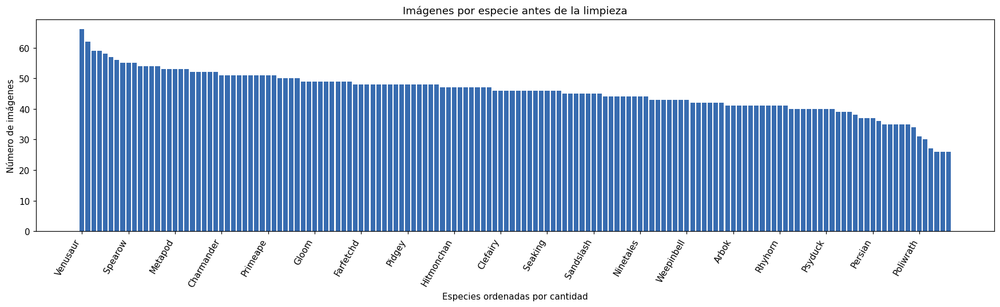

In [17]:
plot_class_distribution(class_counts)

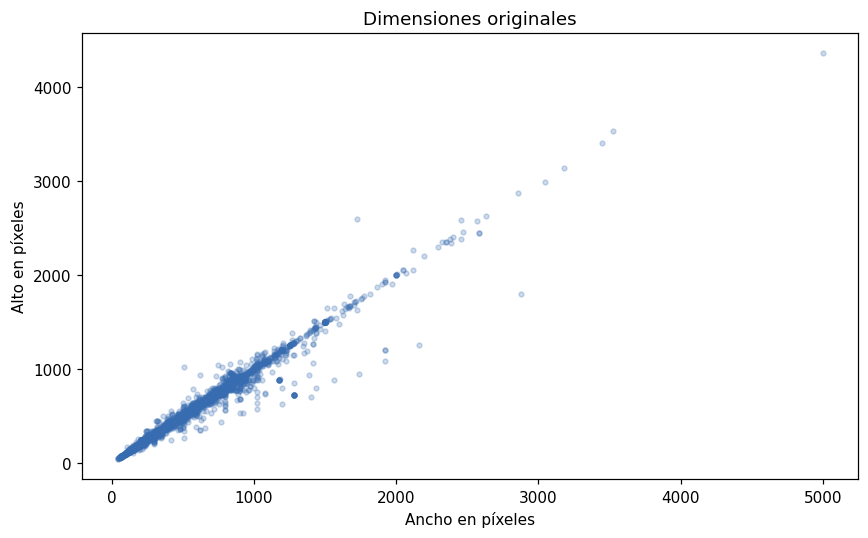

In [18]:
plot_image_dimensions(inventory)

In [19]:
def show_gallery(frame, title, image_root, columns=4):
    """Mostrar una fila por panel; los fallos quedan registrados y no se ocultan."""
    if frame.empty:
        print("No hay imágenes para esta galería.")
        return

    visualization_errors = []
    rows = math.ceil(len(frame) / columns)
    figure, axes = plt.subplots(
        rows, columns, figsize=(3.3 * columns, 3.3 * rows), squeeze=False
    )
    for axis in axes.flat:
        axis.axis("off")

    for axis, record in zip(axes.flat, frame.to_dict("records")):
        path = image_root / record["relative_path"]
        try:
            image = load_rgb(path, BACKGROUND_COLOR)
            image.thumbnail((512, 512))
            axis.imshow(image)
        except (OSError, ValueError, EOFError, Image.DecompressionBombError) as error:
            axis.text(0.5, 0.5, "Error de lectura", ha="center")
            visualization_errors.append(
                {"relative_path": record["relative_path"], "error": str(error)}
            )
        axis.set_title(record["class_name"], fontsize=10)

    figure.suptitle(title)
    show_figure(figure, rect=(0, 0, 1, 0.96))
    return visualization_errors


def select_review_images(inventory):
    """Seleccionar una muestra de clases y los casos de tamaños extremos."""
    metadata_ok = inventory.loc[inventory["header_readable"]].copy()

    rng = np.random.default_rng(126)
    available_classes = sorted(metadata_ok["class_name"].unique())
    chosen_classes = rng.choice(
        available_classes, min(12, len(available_classes)), replace=False
    )
    sample_rows = []

    for class_name in chosen_classes:
        candidates = metadata_ok.loc[metadata_ok["class_name"].eq(class_name)].sort_values(
            "relative_path"
        )
        sample_rows.append(candidates.iloc[int(rng.integers(len(candidates)))])

    sample_images = pd.DataFrame(sample_rows)

    small_images = metadata_ok.sort_values(["min_side", "relative_path"]).head(4)
    aspect_distance = np.abs(np.log(metadata_ok["aspect_ratio"]))
    wide_images = (
        metadata_ok.assign(aspect_distance=aspect_distance)
        .sort_values(["aspect_distance", "relative_path"], ascending=[False, True])
        .head(4)
    )
    review_images = pd.concat([small_images, wide_images]).drop_duplicates("relative_path")
    return sample_images, review_images

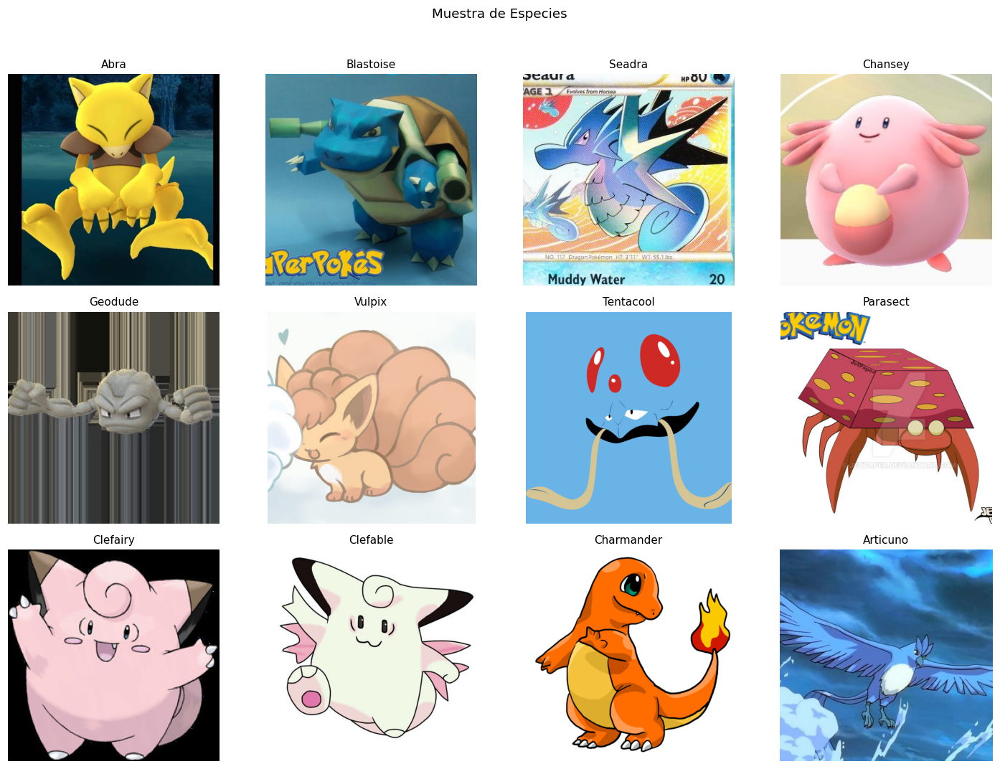

In [20]:
sample_images, review_images = select_review_images(inventory)
sample_errors = show_gallery(sample_images, "Muestra de Especies", image_root)

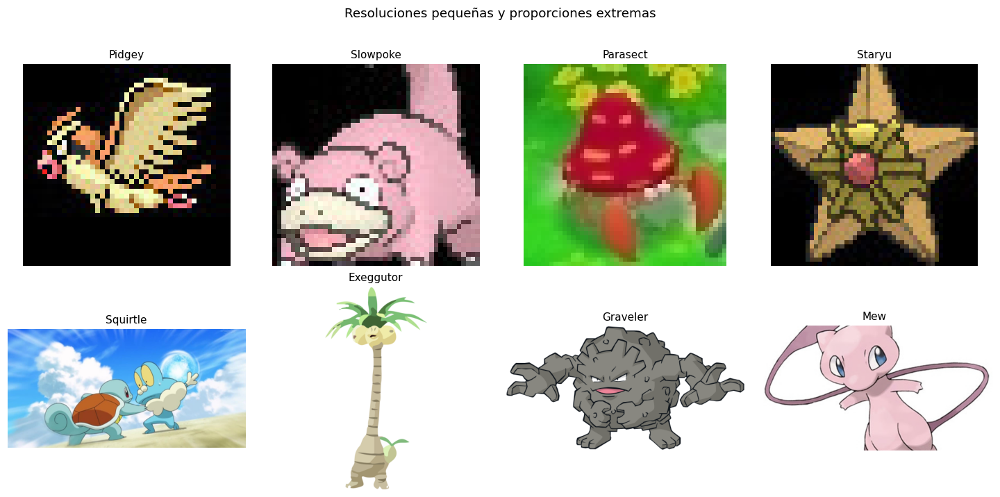

In [21]:
review_errors = show_gallery(
    review_images, "Resoluciones pequeñas y proporciones extremas", image_root
)

### **4. Validación y Duplicados**

In [22]:
def file_digest(path):
    """Calcular SHA-256 leyendo bloques para no cargar el archivo entero en memoria."""
    digest = hashlib.sha256()
    with path.open("rb") as file:
        for block in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def pixel_digest(image):
    """Incluir dimensiones y modo para que la huella identifique los píxeles RGB."""
    digest = hashlib.sha256(f"{image.mode}:{image.size}".encode())
    digest.update(image.tobytes())
    return digest.hexdigest()


def bits_to_hex(bits):
    """Empaquetar 64 decisiones binarias en una cadena hexadecimal estable."""
    return np.packbits(np.asarray(bits).ravel()).tobytes().hex()


def perceptual_hashes(image):
    """Construir pHash DCT de 64 bits y dHash horizontal de 64 bits."""
    gray = image.convert("L")
    small = np.asarray(gray.resize((32, 32), Image.Resampling.LANCZOS), dtype=float)
    low_frequencies = dctn(small, type=2, norm="ortho")[:8, :8]
    median = np.median(low_frequencies.ravel()[1:])
    phash = bits_to_hex(low_frequencies > median)

    edges = np.asarray(gray.resize((9, 8), Image.Resampling.LANCZOS))
    dhash = bits_to_hex(edges[:, 1:] > edges[:, :-1])
    return phash, dhash


def validate_image(relative_path, image_root):
    """Verificar formato, decodificar píxeles y registrar errores sin borrar el origen."""
    path = image_root / relative_path
    result = {
        "relative_path": relative_path,
        "is_valid": False,
        "validation_error": "",
        "file_sha256": "",
        "pixel_sha256": "",
        "prepared_pixel_sha256": "",
        "phash": "",
        "dhash": "",
    }
    try:
        with open_image(path) as image:
            image.verify()
        with open_image(path) as image:
            for frame in range(getattr(image, "n_frames", 1)):
                image.seek(frame)
                image.load()

        rgb = load_rgb(path, BACKGROUND_COLOR)
        prepared = prepare_image(path, TARGET_SIZE, BACKGROUND_COLOR)
        phash, dhash = perceptual_hashes(rgb)
        result.update(
            is_valid=True,
            file_sha256=file_digest(path),
            pixel_sha256=pixel_digest(rgb),
            prepared_pixel_sha256=pixel_digest(prepared),
            phash=phash,
            dhash=dhash,
        )
    except (
        OSError,
        ValueError,
        EOFError,
        SyntaxError,
        Image.DecompressionBombError,
    ) as error:
        result["validation_error"] = f"{type(error).__name__}: {error}"
    return result

In [23]:
def validate_inventory(inventory, image_root):
    """Decodificar todos los archivos, calcular huellas y mostrar avances cada 1000 imágenes."""
    validation_rows = []
    for index, relative_path in enumerate(inventory["relative_path"], start=1):
        validation_rows.append(validate_image(relative_path, image_root))
        if index % 1000 == 0:
            print(f"Validación: {index:,}/{len(inventory):,}")

    validation = pd.DataFrame(validation_rows)
    validated_inventory = inventory.merge(
        validation, on="relative_path", validate="one_to_one"
    )
    valid_images = validated_inventory.loc[validated_inventory["is_valid"]].copy()

    validation_summary = (
        validation["is_valid"]
        .value_counts()
        .rename_axis("is_valid")
        .reset_index(name="images")
    )

    invalid_images = validated_inventory.loc[~validated_inventory["is_valid"]]

    return validated_inventory, validation_summary, invalid_images

In [24]:
validated_inventory, validation_summary, invalid_images = validate_inventory(
    inventory, image_root
)

display(validation_summary)

Validación: 1,000/6,837
Validación: 2,000/6,837
Validación: 3,000/6,837
Validación: 4,000/6,837
Validación: 5,000/6,837
Validación: 6,000/6,837


,is_valid,images
0,True,6837


In [25]:
display(invalid_images[["relative_path", "validation_error"]])

,relative_path,validation_error


In [26]:
def find_similar_pairs(frame, phash_threshold, dhash_threshold):
    """Comparar pares con Hamming y exigir coincidencia en ambos hashes perceptuales."""
    records = frame.sort_values("relative_path").to_dict("records")
    phashes = [int(record["phash"], 16) for record in records]
    dhashes = [int(record["dhash"], 16) for record in records]
    pairs = []

    for left in range(len(records)):
        for right in range(left + 1, len(records)):
            if records[left]["pixel_sha256"] == records[right]["pixel_sha256"]:
                continue  # La igualdad exacta se resuelve por separado.
            phash_distance = (phashes[left] ^ phashes[right]).bit_count()
            if phash_distance > phash_threshold:
                continue
            dhash_distance = (dhashes[left] ^ dhashes[right]).bit_count()
            if dhash_distance <= dhash_threshold:
                pairs.append(
                    {
                        "left_path": records[left]["relative_path"],
                        "right_path": records[right]["relative_path"],
                        "left_class": records[left]["class_name"],
                        "right_class": records[right]["class_name"],
                        "phash_distance": phash_distance,
                        "dhash_distance": dhash_distance,
                    }
                )

    columns = [
        "left_path",
        "right_path",
        "left_class",
        "right_class",
        "phash_distance",
        "dhash_distance",
    ]
    return pd.DataFrame(pairs, columns=columns)


def build_similarity_groups(frame, pairs):
    """Crear componentes conectados estables por igualdad de píxeles y similitud propuesta."""
    paths = sorted(frame["relative_path"])
    parent = {path: path for path in paths}

    def find(path):
        while parent[path] != path:
            parent[path] = parent[parent[path]]
            path = parent[path]
        return path

    def union(left, right):
        root_left, root_right = find(left), find(right)
        if root_left != root_right:
            parent[max(root_left, root_right)] = min(root_left, root_right)

    for hash_column in ["pixel_sha256", "prepared_pixel_sha256"]:
        for _, group_paths in frame.groupby(hash_column)["relative_path"]:
            member_paths = list(group_paths)
            for path in member_paths[1:]:
                union(member_paths[0], path)

    for pair in pairs.itertuples(index=False):
        union(pair.left_path, pair.right_path)

    return {
        path: "group_" + hashlib.sha256(find(path).encode()).hexdigest()[:16]
        for path in paths
    }

In [27]:
def analyze_duplicates(validated_inventory):
    """Revisar copias exactas, proponer similitud y asignar los grupos originales."""
    valid_images = validated_inventory.loc[validated_inventory["is_valid"]].copy()

    similar_pairs = find_similar_pairs(valid_images, PHASH_THRESHOLD, DHASH_THRESHOLD)
    exact_duplicates = valid_images.loc[
        valid_images.duplicated("pixel_sha256", keep=False),
        ["relative_path", "class_name", "file_sha256", "pixel_sha256"],
    ].sort_values(["pixel_sha256", "relative_path"])

    print(
        f"Archivos que pertenecen a conjuntos de copias exactas: {len(exact_duplicates):,}"
    )
    print(f"Pares candidatos por similitud: {len(similar_pairs):,}")

    group_mapping = build_similarity_groups(valid_images, similar_pairs)
    validated_inventory["group_id"] = validated_inventory["relative_path"].map(
        group_mapping
    )
    group_members = validated_inventory.loc[
        validated_inventory["is_valid"], ["relative_path", "class_name", "group_id"]
    ]
    group_sizes = group_members.groupby("group_id").size()

    return validated_inventory, similar_pairs

In [28]:
def show_exact_duplicates(validated_inventory, image_root):
    """Mostrar todas las copias exactas en una figura, identificadas por conjunto."""
    valid_images = validated_inventory.loc[validated_inventory["is_valid"]]
    exact_duplicates = valid_images.loc[
        valid_images.duplicated("pixel_sha256", keep=False),
        ["relative_path", "class_name", "file_sha256", "pixel_sha256"],
    ].sort_values(["pixel_sha256", "relative_path"]).copy()

    exact_duplicates["exact_group"] = (
        exact_duplicates.groupby("pixel_sha256", sort=True).ngroup() + 1
    )
    print(f'Conjuntos de copias exactas: {exact_duplicates["exact_group"].nunique()}')

    if exact_duplicates.empty:
        print("No se encontraron copias exactas.")
        return

    columns = min(4, len(exact_duplicates))
    rows = math.ceil(len(exact_duplicates) / columns)
    figure, axes = plt.subplots(
        rows, columns, figsize=(3.5 * columns, 3.5 * rows), squeeze=False
    )
    for axis in axes.flat:
        axis.axis("off")

    for axis, record in zip(axes.flat, exact_duplicates.itertuples(index=False)):
        path = image_root / record.relative_path
        axis.imshow(load_rgb(path))
        axis.set_title(
            f"Conjunto {record.exact_group}: {record.class_name}\n{path.name}",
            fontsize=8,
        )

    figure.suptitle("Copias exactas agrupadas por igualdad de píxeles")
    show_figure(figure, rect=(0, 0, 1, 0.98))


def show_similar_pairs(inventory, similar_pairs, image_root):
    """Mostrar los pares candidatos para su revisión visual."""
    candidate_gallery = []
    for pair_number, pair in enumerate(
        similar_pairs.itertuples(index=False), start=1
    ):
        for path in [pair.left_path, pair.right_path]:
            record = inventory.loc[inventory["relative_path"].eq(path)].iloc[0].copy()
            record["class_name"] = f'Par {pair_number}: {record["class_name"]}'
            candidate_gallery.append(record)

    show_gallery(
        pd.DataFrame(candidate_gallery),
        "Candidatos a similitud: inspección visual",
        image_root,
        columns=2,
    )

In [29]:
validated_inventory, similar_pairs = analyze_duplicates(validated_inventory)
display(similar_pairs)

Archivos que pertenecen a conjuntos de copias exactas: 24
Pares candidatos por similitud: 31


,left_path,right_path,left_class,right_class,phash_distance,dhash_distance
0,Alolan Sandslash/1fc0f99cc95240138620f2b8a1ba86ec.jpg,Alolan Sandslash/ce945e0129244681a44c925016667ae0 copy.jpg,Alolan Sandslash,Alolan Sandslash,4,4
1,Alolan Sandslash/6525ea05a6aa4932b6aa6307f287d0c3.jpg,Alolan Sandslash/f5d8df5c3e03418d8c92b065a6ba7274.jpg,Alolan Sandslash,Alolan Sandslash,4,3
2,Arbok/ad5202b436824705b1ed0675eaa39454.jpg,Arbok/fea033db0e48467090dd3067e7769d3d.jpg,Arbok,Arbok,2,1
3,Charmeleon/c2f40ab63f3d4e70a3178156e70d46e2.jpg,Charmeleon/e92e45465b6645f6bcf6367d13d21a0f.jpg,Charmeleon,Charmeleon,0,3
4,Clefairy/bcb44348ad7644b2b9ddd3cfdcdbf313.jpg,Clefairy/da5f403219a741eab4e86c34ab5f52d3.jpg,Clefairy,Clefairy,2,6
5,Dodrio/4c310176bd664c0aab3f997323dee002.jpg,Doduo/616c2218a8f84f6aa879fc141b395b7a.jpg,Dodrio,Doduo,4,6
6,Dugtrio/ae770e3e15af4837869e61444c330cc3.jpg,Dugtrio/baf1c7f8608e4a0582432818e13ce0c9.jpg,Dugtrio,Dugtrio,4,3
7,Electrode/7fe8852c83644ac18026fc3ffdf017b2.jpg,Electrode/de6b731598dc433ca4e600183dd91029.jpg,Electrode,Electrode,4,6
8,Fearow/4a2cad2797754dc4968083a1f718d871.jpg,Fearow/8034ffa695c74b0aa4400e9768c76cd2.jpg,Fearow,Fearow,2,1
9,Grimer/6e8e877680bb4664966d0128f76223a9.jpg,Muk/d99a419aea0f414a86f5b28d29cf4c6f.jpg,Grimer,Muk,0,0


Conjuntos de copias exactas: 12


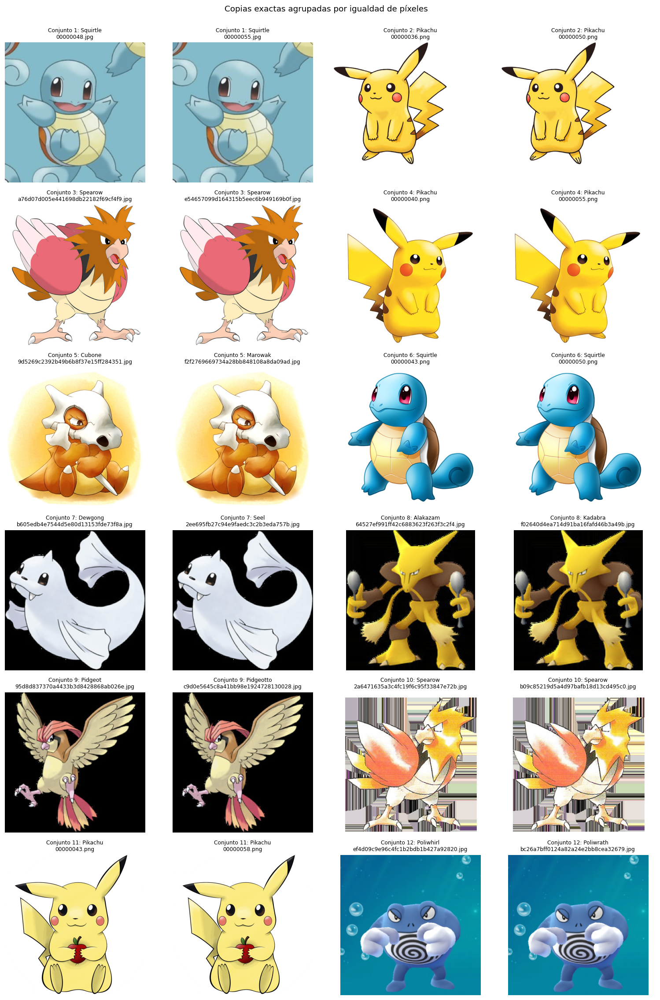

In [30]:
show_exact_duplicates(validated_inventory, image_root)




In [31]:
show_similar_pairs(inventory, similar_pairs, image_root)

### **5. Revisión Manual y Limpieza**

In [32]:
# Conservar las decisiones de la revisión visual del dataset original.
LABEL_CORRECTIONS = {}

MANUAL_EXCLUSIONS = {
    "Poliwhirl/ef4d09c9e96c4fc1b2bdb1b427a92820.jpg": "No contiene la especie indicada",
    "Seel/2ee695fb27c94e9faedc3c2b3eda757b.jpg": "No contiene la especie indicada",
    "Kadabra/f02640d4ea714d91ba16fafd46b3a49b.jpg": "No contiene la especie indicada",
    "Marowak/f2f2769669734a28bb848108a8da09ad.jpg": "No contiene la especie indicada",
    "Pidgeot/95d8d837370a4433b3d8428868ab026e.jpg": "No contiene la especie indicada",
    "Muk/d99a419aea0f414a86f5b28d29cf4c6f.jpg": "No contiene la especie indicada",
    "Kingler/c93362919a154cf4ac09703cf3819f33.jpg": "No contiene la especie indicada",
    "Mankey/17d9534325c148a083b4e1526ca3646c.jpg": "No contiene la especie indicada",
    "Poliwhirl/82158b93b226423bbe2cbe3c7dd6cdfd.jpg": "No contiene la especie indicada",
    "Alolan Sandslash/ce945e0129244681a44c925016667ae0 copy.jpg": "Imagen duplicada",
    "Alolan Sandslash/f5d8df5c3e03418d8c92b065a6ba7274.jpg": "Imagen duplicada",
    "Arbok/fea033db0e48467090dd3067e7769d3d.jpg": "Imagen duplicada",
    "Charmeleon/e92e45465b6645f6bcf6367d13d21a0f.jpg": "Imagen duplicada",
    "Clefairy/bcb44348ad7644b2b9ddd3cfdcdbf313.jpg": "Imagen duplicada",
    "Dugtrio/ae770e3e15af4837869e61444c330cc3.jpg": "Imagen duplicada",
    "Electrode/de6b731598dc433ca4e600183dd91029.jpg": "Imagen duplicada",
    "Fearow/4a2cad2797754dc4968083a1f718d871.jpg": "Imagen duplicada",
    "Jigglypuff/f663a8c63e394c719a8c8c8d5ee90ac7.jpg": "Imagen duplicada",
    "Kadabra/b0f6a7ee5f1a46b59eff40730bdea34c.jpg": "Imagen duplicada",
    "Mew/1d11248aa89e4d9eb9cc724607362f95.jpg": "Imagen duplicada",
    "Mewtwo/00000005.png": "Imagen duplicada",
    "Nidoqueen/cff767ad0a76404fb14744529cc554c0.jpg": "Imagen duplicada",
    "Nidorina/dcd5fccb6e0a4385b38e6e98aec7f1a5.jpg": "Imagen duplicada",
    "Persian/d4e638d4c95a476c8c5c6b9b2f748197.jpg": "Imagen duplicada",
    "Pidgeotto/145e76f0fdca43d884539cc9bfa8e9a9.jpg": "Imagen duplicada",
    "Pikachu/00000001.png": "Imagen duplicada",
    "Pikachu/00000009.png": "Imagen duplicada",
    "Poliwag/f7d38a9106f64a7280f3eb243ad89624.jpeg": "Imagen duplicada",
    "Poliwhirl/235e136ad0564826a1fd12410ff87d75.jpg": "Imagen duplicada",
    "Poliwhirl/e1fba10f22ee433b93fd87cf26f35656.jpg": "Imagen duplicada",
    "Rattata/7523f3d43c3948068206df819f447c85.jpg": "Imagen duplicada",
    "Sandshrew/4f27a580fc3d4316a281f8037d70db34.jpg": "Imagen duplicada",
    "Scyther/29a4a5a77fc142148145fdc7ecd78976.jpg": "Imagen duplicada",
    "Vaporeon/6ced40269c914c0bb713ec7981fd636f.jpg": "Imagen duplicada",
    "Vulpix/c7a27dd6c23c4e069a8d3fa6d5449456.jpeg": "Imagen duplicada"
}

In [33]:
def check_manual_decisions(inventory, label_corrections, manual_exclusions):
    """Comprobar que las correcciones y exclusiones tengan rutas y motivos válidos."""
    known_paths = set(inventory["relative_path"])
    known_classes = set(inventory["class_name"])
    for relative_path, correction in label_corrections.items():
        if (
            relative_path not in known_paths
            or correction.get("class_name") not in known_classes
        ):
            raise ValueError(f"Corrección con ruta o clase desconocida: {relative_path}")
        if not correction.get("reason", "").strip():
            raise ValueError(f"La corrección necesita un motivo: {relative_path}")

    for relative_path, reason in manual_exclusions.items():
        if relative_path not in known_paths or not reason.strip():
            raise ValueError(f"Exclusión sin ruta válida o motivo: {relative_path}")

In [34]:
def review_labels(validated_inventory, label_corrections, manual_exclusions):
    """Aplicar las decisiones manuales y detectar conflictos de etiquetas aún pendientes."""
    label_audit = validated_inventory.copy()
    label_audit["original_class_name"] = label_audit["class_name"]
    label_audit["manual_review_status"] = "not_manually_reviewed"
    label_audit["manual_reason"] = ""

    for relative_path, correction in label_corrections.items():
        selected = label_audit["relative_path"].eq(relative_path)
        label_audit.loc[selected, "class_name"] = correction["class_name"]
        label_audit.loc[selected, "manual_review_status"] = "label_corrected"
        label_audit.loc[selected, "manual_reason"] = correction["reason"]

    for relative_path, reason in manual_exclusions.items():
        selected = label_audit["relative_path"].eq(relative_path)
        label_audit.loc[selected, "manual_review_status"] = "manually_excluded"
        label_audit.loc[selected, "manual_reason"] = reason

    # Buscar la misma imagen con etiquetas distintas después de las decisiones explícitas.
    eligible_labels = label_audit.loc[
        label_audit["is_valid"] & ~label_audit["relative_path"].isin(manual_exclusions)
    ]
    labels_per_hash = eligible_labels.groupby("pixel_sha256")["class_name"].nunique()
    conflicting_hashes = set(labels_per_hash.loc[labels_per_hash.gt(1)].index)
    label_audit["exact_label_conflict"] = label_audit["is_valid"] & label_audit[
        "pixel_sha256"
    ].isin(conflicting_hashes)
    conflict_report = label_audit.loc[
        label_audit["exact_label_conflict"],
        ["relative_path", "original_class_name", "class_name", "pixel_sha256"],
    ]

    # Ordenar por huella para mostrar juntas las imágenes idénticas con etiquetas diferentes.
    conflict_preview = (
        label_audit.loc[label_audit["exact_label_conflict"]]
        .sort_values(["pixel_sha256", "relative_path"])
        .head(10)
    )
    return label_audit, conflict_report, conflict_preview

In [35]:
def clean_dataset(label_audit, manual_exclusions, known_classes):
    """Excluir los casos revisados y conservar un representante por copia exacta de la misma clase."""
    cleaning_decisions = label_audit.copy()
    cleaning_decisions["action"] = "keep"
    cleaning_decisions["reason"] = "valid_image"
    cleaning_decisions["duplicate_of"] = ""

    invalid = ~cleaning_decisions["is_valid"]
    cleaning_decisions.loc[invalid, ["action", "reason"]] = ["exclude", "invalid_file"]

    manual = cleaning_decisions["relative_path"].isin(manual_exclusions)
    cleaning_decisions.loc[manual, ["action", "reason"]] = ["exclude", "manual_exclusion"]

    conflict = cleaning_decisions["exact_label_conflict"] & cleaning_decisions["action"].eq("keep")
    cleaning_decisions.loc[conflict, ["action", "reason"]] = [
        "exclude",
        "unresolved_exact_label_conflict",
    ]

    # Eliminar redundancia solo dentro de la misma etiqueta corregida.
    eligible = cleaning_decisions.loc[cleaning_decisions["action"].eq("keep")].sort_values(
        "relative_path"
    )
    for _, members in eligible.groupby(["class_name", "pixel_sha256"], sort=True):
        representative = members.iloc[0]["relative_path"]
        duplicates = members.index[1:]
        cleaning_decisions.loc[duplicates, "action"] = "exclude"
        cleaning_decisions.loc[duplicates, "reason"] = "redundant_exact_copy"
        cleaning_decisions.loc[duplicates, "duplicate_of"] = representative

    clean_manifest = cleaning_decisions.loc[cleaning_decisions["action"].eq("keep")].copy()
    missing_classes = known_classes - set(clean_manifest["class_name"])
    if missing_classes:
        raise ValueError(
            f"Clases sin imágenes después de la limpieza: {sorted(missing_classes)}"
        )

    class_names = sorted(clean_manifest["class_name"].unique())
    class_to_index = {name: index for index, name in enumerate(class_names)}
    clean_manifest["class_index"] = clean_manifest["class_name"].map(class_to_index)
    clean_manifest = clean_manifest.sort_values("relative_path").reset_index(drop=True)

    display(cleaning_decisions.groupby(["action", "reason"]).size().reset_index(name="images"))

    return clean_manifest, class_names

In [36]:
check_manual_decisions(inventory, LABEL_CORRECTIONS, MANUAL_EXCLUSIONS)
label_audit, conflict_report, conflict_preview = review_labels(
    validated_inventory, LABEL_CORRECTIONS, MANUAL_EXCLUSIONS
)
display(conflict_report)

,relative_path,original_class_name,class_name,pixel_sha256


In [37]:
conflict_errors = show_gallery(
    conflict_preview, "Mismos píxeles con etiquetas diferentes", image_root, columns=2
)

No hay imágenes para esta galería.


In [38]:
clean_manifest, class_names = clean_dataset(
    label_audit, MANUAL_EXCLUSIONS, set(inventory["class_name"])
)

,action,reason,images
0,exclude,manual_exclusion,35
1,exclude,redundant_exact_copy,7
2,keep,valid_image,6795


### **6. Particiones y Preprocesamiento**

In [39]:
def choose_group_split(frame):
    """Buscar cobertura completa por clase sin romper grupos ni usar métricas de modelos."""
    frame = frame.sort_values("relative_path").reset_index(drop=True)
    independent_groups = frame.groupby("class_name")["group_id"].nunique()
    if independent_groups.min() < 3:
        raise ValueError(
            "Alguna especie tiene menos de tres grupos independientes; revisar D06."
        )

    labels = frame["class_index"].to_numpy()
    groups = frame["group_id"].to_numpy()
    n_classes = frame["class_index"].nunique()
    totals = np.bincount(labels, minlength=n_classes)
    best_score = np.inf
    best_assignment = None
    best_metadata = None

    for attempt in range(SPLIT_ATTEMPTS):
        splitter = StratifiedGroupKFold(
            n_splits=SPLIT_FOLDS, shuffle=True, random_state=SEED + attempt
        )
        fold_assignment = np.empty(len(frame), dtype=int)
        for fold, (_, held_out) in enumerate(splitter.split(frame, labels, groups)):
            fold_assignment[held_out] = fold

        fold_counts = np.array(
            [
                np.bincount(labels[fold_assignment == fold], minlength=n_classes)
                for fold in range(SPLIT_FOLDS)
            ]
        )
        complete_folds = np.flatnonzero((fold_counts > 0).all(axis=1))

        for validation_fold, test_fold in combinations(complete_folds, 2):
            evaluation_counts = fold_counts[[validation_fold, test_fold]]
            training_counts = totals - evaluation_counts.sum(axis=0)
            split_counts = np.vstack([training_counts, evaluation_counts])
            if (split_counts == 0).any():
                continue
            ratios = split_counts / totals[None, :]
            score = np.mean((ratios - TARGET_RATIOS[:, None]) ** 2)
            if score < best_score:
                assignment = np.full(len(frame), "train", dtype=object)
                assignment[fold_assignment == validation_fold] = "val"
                assignment[fold_assignment == test_fold] = "test"
                best_score = score
                best_assignment = assignment
                best_metadata = {
                    "seed": SEED + attempt,
                    "validation_fold": int(validation_fold),
                    "test_fold": int(test_fold),
                    "class_ratio_mse": float(score),
                }

    if best_assignment is None:
        raise ValueError(
            "No se encontró cobertura completa sin romper grupos. Revisar D06 y D09."
        )
    return frame.assign(split=best_assignment), best_metadata

In [40]:
def summarize_splits(splits):
    """Comprobar cobertura de clases, separación de grupos y distribución final."""
    split_order = ["train", "val", "test"]
    class_split_counts = pd.crosstab(splits["class_name"], splits["split"]).reindex(
        columns=split_order
    )

    assert splits["relative_path"].is_unique, "Hay rutas repetidas."
    assert (
        splits.groupby("group_id")["split"].nunique().max() == 1
    ), "Hay grupos compartidos."
    assert (class_split_counts > 0).all().all(), "Falta alguna especie en una partición."

    split_summary = (
        splits.groupby("split")
        .agg(
            images=("relative_path", "size"),
            classes=("class_name", "nunique"),
            groups=("group_id", "nunique"),
        )
        .reindex(split_order)
    )
    split_summary["percentage"] = 100 * split_summary["images"] / len(splits)

    return split_summary.round(2), class_split_counts

In [41]:
def show_preprocessing(splits, image_root):
    """Comparar las mismas imágenes de entrenamiento antes y después del preprocesamiento."""
    # La demostración utiliza entrenamiento, evitando seleccionar imágenes de prueba.
    transform_samples = splits.loc[splits["split"].eq("train")].sample(
        n=min(3, int(splits["split"].eq("train").sum())), random_state=SEED
    )
    figure, axes = plt.subplots(
        len(transform_samples), 2, figsize=(7, 3.2 * len(transform_samples)), squeeze=False
    )

    for row, record in enumerate(transform_samples.to_dict("records")):
        source_path = image_root / record["relative_path"]
        original = load_rgb(source_path, BACKGROUND_COLOR)
        prepared = prepare_image(source_path, TARGET_SIZE, BACKGROUND_COLOR)
        axes[row, 0].imshow(original)
        axes[row, 1].imshow(prepared)
        axes[row, 0].set_title(f'{record["class_name"]}: RGB original')
        axes[row, 1].set_title("Entrada preparada: 224 × 224")
        for axis in axes[row]:
            axis.axis("off")

    show_figure(figure)

In [42]:
def prepare_dataset_images(splits, image_root):
    """Escribir las copias PNG y comprobar que sus píxeles coincidan con la preparación validada."""
    prepared_records = []
    for index, record in enumerate(splits.to_dict("records"), start=1):
        source_path = image_root / record["relative_path"]
        image_id = hashlib.sha256(record["relative_path"].encode()).hexdigest()[:20]
        relative_output = Path("images") / record["class_name"] / f"{image_id}.png"
        output_path = RUN_DIR / relative_output
        output_path.parent.mkdir(parents=True, exist_ok=True)

        prepared = prepare_image(source_path, TARGET_SIZE, BACKGROUND_COLOR)
        prepared.save(output_path, format="PNG")
        prepared_records.append(
            {
                "relative_path": record["relative_path"],
                "prepared_path": relative_output.as_posix(),
                "prepared_file_sha256": file_digest(output_path),
                "written_pixel_sha256": pixel_digest(prepared),
            }
        )
        if index % 1000 == 0:
            print(f"Imágenes preparadas: {index:,}/{len(splits):,}")

    prepared_files = pd.DataFrame(prepared_records)
    splits = splits.merge(prepared_files, on="relative_path", validate="one_to_one")
    assert splits["prepared_path"].is_unique, "Colisión de nombres de salida."
    assert (
        splits["prepared_pixel_sha256"].eq(splits["written_pixel_sha256"]).all()
    ), "Preparación inconsistente."
    print(f"Copias PNG preparadas: {len(splits):,}")

    return splits

In [43]:
splits, split_metadata = choose_group_split(clean_manifest)
split_summary, class_split_counts = summarize_splits(splits)
display(split_summary)

,images,classes,groups,percentage
split,,,,
train,4853,150,4853,71.42
val,972,150,971,14.30
test,970,150,970,14.28


In [44]:
display(class_split_counts.head(15))

split,train,val,test
class_name,,,
Abra,25,8,2
Aerodactyl,24,5,6
Alakazam,19,5,2
Alolan Sandslash,28,5,6
Arbok,28,6,6
Arcanine,25,7,9
Articuno,30,11,4
Beedrill,24,3,7
Bellsprout,27,7,6


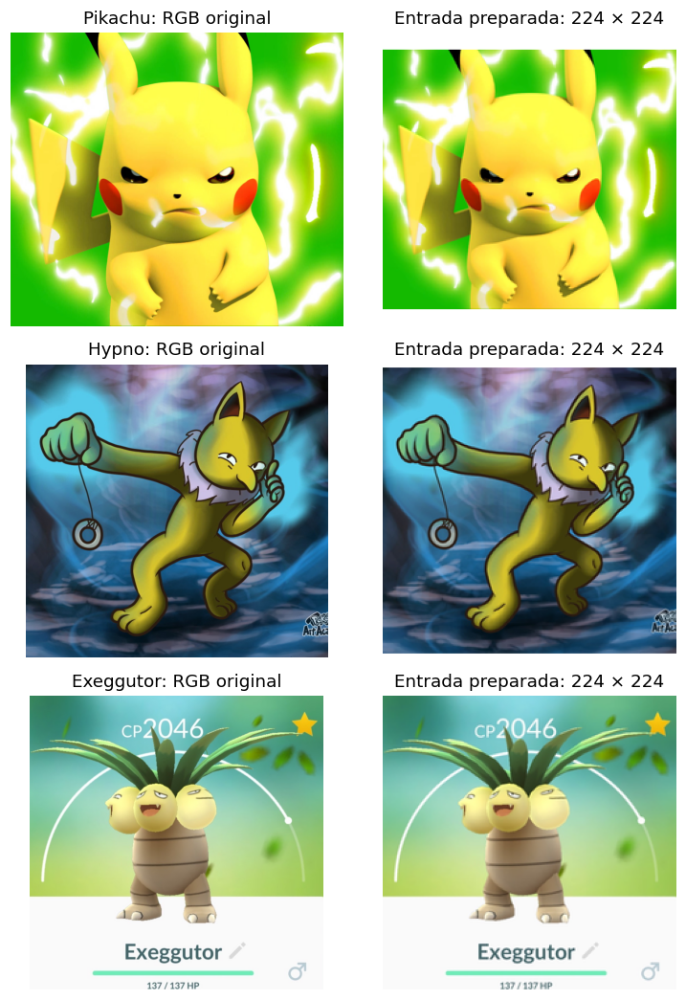

In [45]:
show_preprocessing(splits, image_root)

In [46]:
splits = prepare_dataset_images(splits, image_root)

Imágenes preparadas: 1,000/6,795
Imágenes preparadas: 2,000/6,795
Imágenes preparadas: 3,000/6,795
Imágenes preparadas: 4,000/6,795
Imágenes preparadas: 5,000/6,795
Imágenes preparadas: 6,000/6,795
Copias PNG preparadas: 6,795


### **7. Exportación del Dataset**

In [47]:
def build_export_manifest(splits):
    """Conservar las mismas columnas, rutas, etiquetas, particiones y huellas."""
    export_manifest = (
        pd.DataFrame(
            {
                "relative_path": splits["prepared_path"],
                "source_relative_path": splits["relative_path"],
                "class_name": splits["class_name"],
                "class_index": splits["class_index"],
                "split": splits["split"],
                "group_id": splits["group_id"],
                "source_file_sha256": splits["file_sha256"],
                "source_pixel_sha256": splits["pixel_sha256"],
                "prepared_file_sha256": splits["prepared_file_sha256"],
                "prepared_pixel_sha256": splits["prepared_pixel_sha256"],
            }
        )
        .sort_values("relative_path")
        .reset_index(drop=True)
    )

    return export_manifest

In [48]:
def verify_dataset_archive(archive_path, export_manifest):
    """Reabrir el ZIP, verificar huellas y comprobar una imagen RGB de cada partición."""
    split_order = ["train", "val", "test"]

    checksums = pd.DataFrame(
        [
            {
                "relative_path": path.relative_to(RUN_DIR).as_posix(),
                "size_bytes": path.stat().st_size,
                "sha256": file_digest(path),
            }
            for path in sorted(RUN_DIR.rglob("*"))
            if path.is_file() and path.name != "file_checksums.csv"
        ]
    )

    # Reabrir el paquete y verificar sus bytes, sin depender de la carpeta de origen.
    with ZipFile(archive_path) as archive:
        assert archive.testzip() is None, "El ZIP contiene un miembro dañado."
        archived_manifest = pd.read_csv(archive.open("splits.csv"))
        pd.testing.assert_frame_equal(archived_manifest, export_manifest)
        for record in checksums.to_dict("records"):
            content_hash = hashlib.sha256(archive.read(record["relative_path"])).hexdigest()
            assert content_hash == record["sha256"], record["relative_path"]

        # Extraer en una ubicación distinta y comprobar una imagen de cada partición.
        with TemporaryDirectory(prefix="pokemon_package_check_") as temporary:
            relocated_root = Path(temporary)
            archive.extract("splits.csv", relocated_root)
            relocated_manifest = pd.read_csv(relocated_root / "splits.csv")
            for split_name in split_order:
                relative_path = relocated_manifest.loc[
                    relocated_manifest["split"].eq(split_name), "relative_path"
                ].iloc[0]
                archive.extract(relative_path, relocated_root)
                with Image.open(relocated_root / relative_path) as image:
                    image.load()
                    assert image.mode == "RGB" and image.size == TARGET_SIZE

In [49]:
def export_prepared_dataset(splits, class_names):
    """Guardar únicamente las imágenes preparadas, splits.csv y class_names.json."""
    export_manifest = build_export_manifest(splits)
    export_manifest.to_csv(RUN_DIR / "splits.csv", index=False)
    (RUN_DIR / "class_names.json").write_text(
        json.dumps(class_names, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    archive_path = RUN_DIR.parent / f"prepared_dataset_{RUN_ID}.zip"
    with ZipFile(archive_path, "w", compression=ZIP_DEFLATED) as archive:
        for path in sorted(RUN_DIR.rglob("*")):
            if path.is_file():
                archive.write(path, arcname=path.relative_to(RUN_DIR).as_posix())
    verify_dataset_archive(archive_path, export_manifest)
    print(f"Paquete verificado: {archive_path}")
    print(f"Tamaño: {archive_path.stat().st_size / 1024**2:.2f} MiB")
    print(f"SHA-256 del paquete: {file_digest(archive_path)}")

    return archive_path

In [50]:
archive_path = export_prepared_dataset(splits, class_names)

Paquete verificado: /content/pokemon_project/prepared_runs/prepared_dataset_20261104T022644549814Z.zip
Tamaño: 406.06 MiB
SHA-256 del paquete: 0f2b26e68451eb4b0c5aa631ad5786c90eefb805af5d859acce59ee09eb26fca


In [51]:
DOWNLOAD_PACKAGE = True

if DOWNLOAD_PACKAGE:
    try:
        from google.colab import files
    except ImportError:
        print(f"Fuera de Colab, copiar el paquete desde: {archive_path}")
    else:
        files.download(str(archive_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>